# Theoretical analysis how the choice of coalescent prior influences node heigth estimation
We consider an example of two homochronously sampled tips and the time to their most recent common ancestor.

We define a sequence length $L$, $k$ mutations and a mutation rate $\mu$ assuming the infinite site model.
The population size is modeled as a function of time $N(t)$. This gives the following posterior distribution of $t_{MRCA}$:
$$
P(t_{MRCA} \mid k, N) = \frac{P(k \mid t_{MRCA})\cdot P(t_{MRCA} \mid N)}{P(k \mid N)} \propto P(k \mid t_{MRCA})\cdot Pt_{MRCA} \mid N)
$$

with a likelihood function based on mutational signal: 
$$
P(k|t_{MRCA}) = \frac{(2 \cdot \mu \cdot L \cdot t_{MRCA})^k}{k!} \, e^{-2 \mu L t_{MRCA}}
$$ 
and a coalescent prior:
$$
P(t_{MRCA}|N) = \frac{1}{N(t_{\text{present}} - t_{MRCA}) \cdot g} \cdot e^{- \int_0^{t_{MRCA}} \frac{1}{g \cdot N(t_{\text{present}} - s)} \, ds}
$$

Set generation time $g = 1$.


Three different population size models are considered:
1. Constant-size coalescent prior with constant population size $N(t) = N_0$: 
$$
P(t_{\mathrm{MRCA}} \mid N) = \frac{1}{N} e^{-\frac{1}{N} t_{\mathrm{MRCA}}}
$$
2. Exponential growth coalescent prior with the population size decreasing backwards in time $N(t) = N_{\mathrm{present}} e^{-\beta t}$:
$$
P(t_{\mathrm{MRCA}}|N) = \frac{1}{N_{\mathrm{present}} \cdot e^{-\beta t_{\mathrm{MRCA}}} } \cdot e^{-\frac{1}{N_{\mathrm{present}} \cdot \beta} \left( e^{\beta t_{\mathrm{MRCA}}} - 1 \right)}
$$
3. Bottleneck coalescent prior. We consider a population bottleneck, with all times measured backward from the present. The parameters $\Delta t_{\mathrm{b-start}}$ and $\Delta t_{\mathrm{b-end}}$ denote the more recent and older boundaries of the bottleneck, respectively, such that $\Delta t_{\mathrm{b-start}} < \Delta t_{\mathrm{b-end}}$. The population size is modeled as with the corresponding coalescent prior:
$$
    N(s)= \begin{cases} N_{\mathrm{low}}, & \Delta t_{\mathrm{b-start}} \le s \le \Delta t_{\mathrm{b-end}},\\ N_{\mathrm{high}}, &  \text{otherwise}. \end{cases}
$$
$$
    P(t_{MRCA}|N)= 
    \begin{cases}
        \frac{1}{N_{\text{high}}} \cdot \exp\left(-\frac{t_{\text{MRCA}}}{N_{\text{high}}}\right)
        & \text{if } t_{\text{MRCA}} < \Delta t_{\text{b-start}} \\[12pt]
        
        \frac{1}{N_{\text{low}}} \cdot \exp\left( - \left( 
        \frac{\Delta t_{\text{b-start}}}{N_{\text{high}}} 
        + \frac{t_{\text{MRCA}} - \Delta t_{\text{b-start}}}{N_{\text{low}}} 
        \right) \right)
        & \text{if } \Delta t_{\text{b-start}} \le t_{\text{MRCA}} \le \Delta t_{\text{b-end}} \\[12pt]
        
        \frac{1}{N_{\text{high}}} \cdot \exp\left( - \left( 
        \frac{\Delta t_{\text{b-start}}}{N_{\text{high}}} 
        + \frac{\Delta t_{\text{b-end}} - \Delta t_{\text{b-start}}}{N_{\text{low}}}
        + \frac{t_{\text{MRCA}} - \Delta t_{\text{b-end}}}{N_{\text{high}}}
        \right) \right)
        & \text{if } t_{\text{MRCA}} > \Delta t_{\text{b-end}}
    \end{cases}
$$


In [1]:
import numpy as np

from src.metrics import calculate_rel_median_shift, calculate_wasserstein_dist, calculate_median_shift
from src.evaluate_prior_impact import create_prior_influence_metric_df_bottleneck, create_prior_influence_metric_df_const_pathogen, create_prior_influence_metric_df_pathogen_exp, create_prior_influence_metric_df_exp_pathogen, create_prior_influence_metric_df_bottleneck_pathogen
from src.plotting.plot_prob_functions import plot_tMRCA_constN, plot_tMRCA_expN_present, plot_tMRCA_bottleneck, plot_mutational_signal_std, plot_mutational_signal_std_by_rate
from src.plotting.plot_metric_comparison import plot_metric_summary, plot_pathogen_error_summary

## Pathogen scenarios

When only taking into account the mutational signal without considering prior information on the population size, the Maximum Likelihood Estimate (MLE) of $t_{MRCA}$ under this model is $\frac{k}{\lambda}$. The posterior mean and variance under a flat prior are then $\mathbb{E}\!\left[t_{MRCA}\right] = \frac{k+1}{2 \mu L}$ and $\mathrm{Var}\!\left[t_{MRCA}\right] = \frac{k+1}{\left( 2 \mu L \right)^2}$.
Scaling both, the mutation count $k$ and the rate $\lambda$ by a factor $\alpha > 1$, reduces the variance and thus increases the mutational signal while keeping the MLE of the $t_{MRCA}$ constant. Conversely, using a scaling factor $\alpha < 1$ decreases the mutational signal by increasing the variance.

We relate the theoretical results to four biologically plausible levels of mutational signal, expressed as expected mutations per genome per year.
1. The highest level, 50, serves as an upper bound for rapidly evolving RNA viruses. For comparison, the $29'903$ bp Wuhan-Hu-1 reference genome of SARS-CoV-2 and a substitution rate of approximately $10^{-3}$ per site per year imply about 30 mutations per genome per year.
2. We use 5 mutations per analysed sequence per year to represent highly variable viral genes or regions. Human \emph{Influenza A}(H3N2) HA1 with a rate of approximately $5 \cdot 10^{-3}$ substitutions per site per year across roughly 990 sites provides one example. Similarly, the full HA coding region of human \emph{Influenza A}(H1N1), at approximately $1'720$ sites and an estimated rate of $3.3 \cdot 10^{-3}$ substitutions per site per year, accumulates about 5.6 substitutions per year.
3. For slowly evolving bacterial pathogens, we use 0.5 mutations per genome per year as an intermediate illustrative value. Published estimates for \emph{Mycobacterium tuberculosis} of approximately $4.6 \cdot 10^{-8}$ substitutions per site per year across a 4.4-million-base-pair genome imply about 0.20 substitutions per year. Estimates for \emph{Bordetella pertussis} of $2.24 \cdot 10^{-7}$ per site per year across a 4.1-million-base-pair reference genome imply about 0.92 substitutions per year.
4. Finally, we use 0.05 mutations per analysed sequence per year to approximate analyses restricted to a small portion of a bacterial genome.

All mutational signal levels were generated by varying the scaling parameter $\alpha$ while keeping the MLE of the $t_{MRCA}$ under the flat prior constant at 20 years.

In [2]:
L = 5e6
base_mu = 1e-6
print(f"Base mutations per genome per year: {base_mu * L}")
N_values = [10, 100, 1000, 10000, 100000]  # Rows
alpha_values = [0.01, 0.1, 1, 10]  # Columns
base_k = 200
t_max = 500  # Maximum tMRCA to consider

print(f"MLE of tMRCA based on likelihood only in years: {base_k / (2 * base_mu * L)}")
t_MRCA_mle = 20
print(f"Choose k: {2 * base_mu * L * t_MRCA_mle}")

Base mutations per genome per year: 5.0
MLE of tMRCA based on likelihood only in years: 20.0
Choose k: 200.0


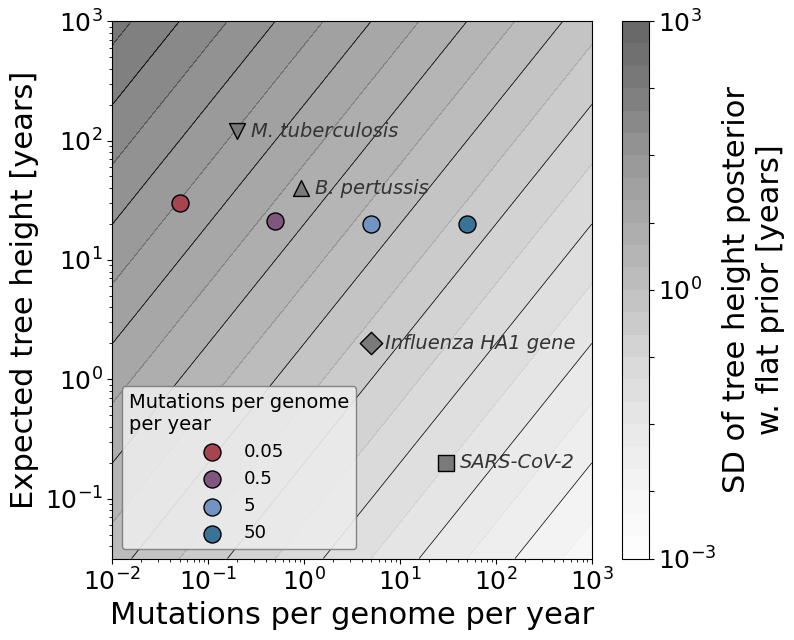

In [3]:
plot_mutational_signal_std(
    base_mu, L, base_k, alpha_values,
    pathogens={"SARS-CoV-2": ((0.2), 30), "B. pertussis": (40, 0.92), "Influenza HA1 gene": ((2), 5), "M. tuberculosis": (120, 0.20)},   # label: (tMRCA in years, mutations/genome/year)
    save_path="figures/mutational_signal_std_map.pdf",
)

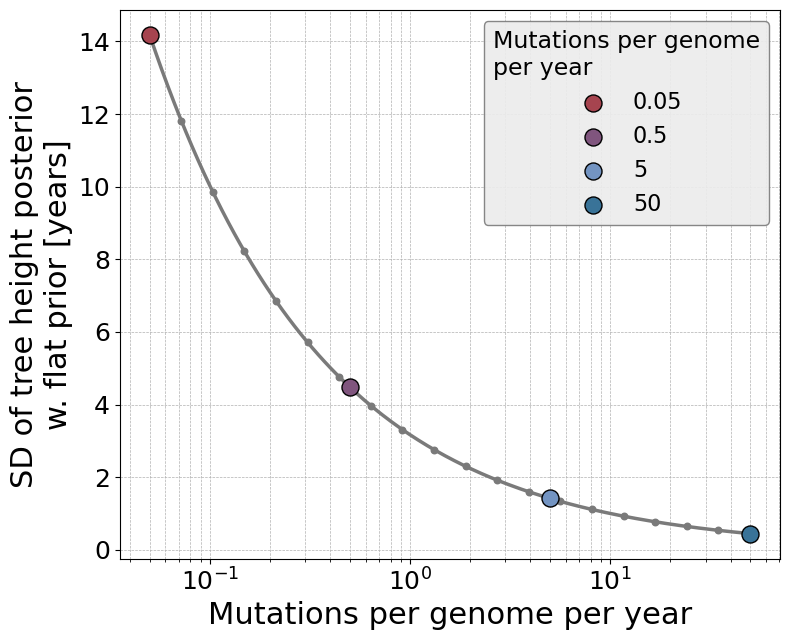

In [4]:
plot_mutational_signal_std_by_rate(
    base_mu, L, base_k, alpha_values,
    log_y = False,
    save_path="figures/mutational_signal_std_by_rate.pdf",
)

## Detailed view of probability densities

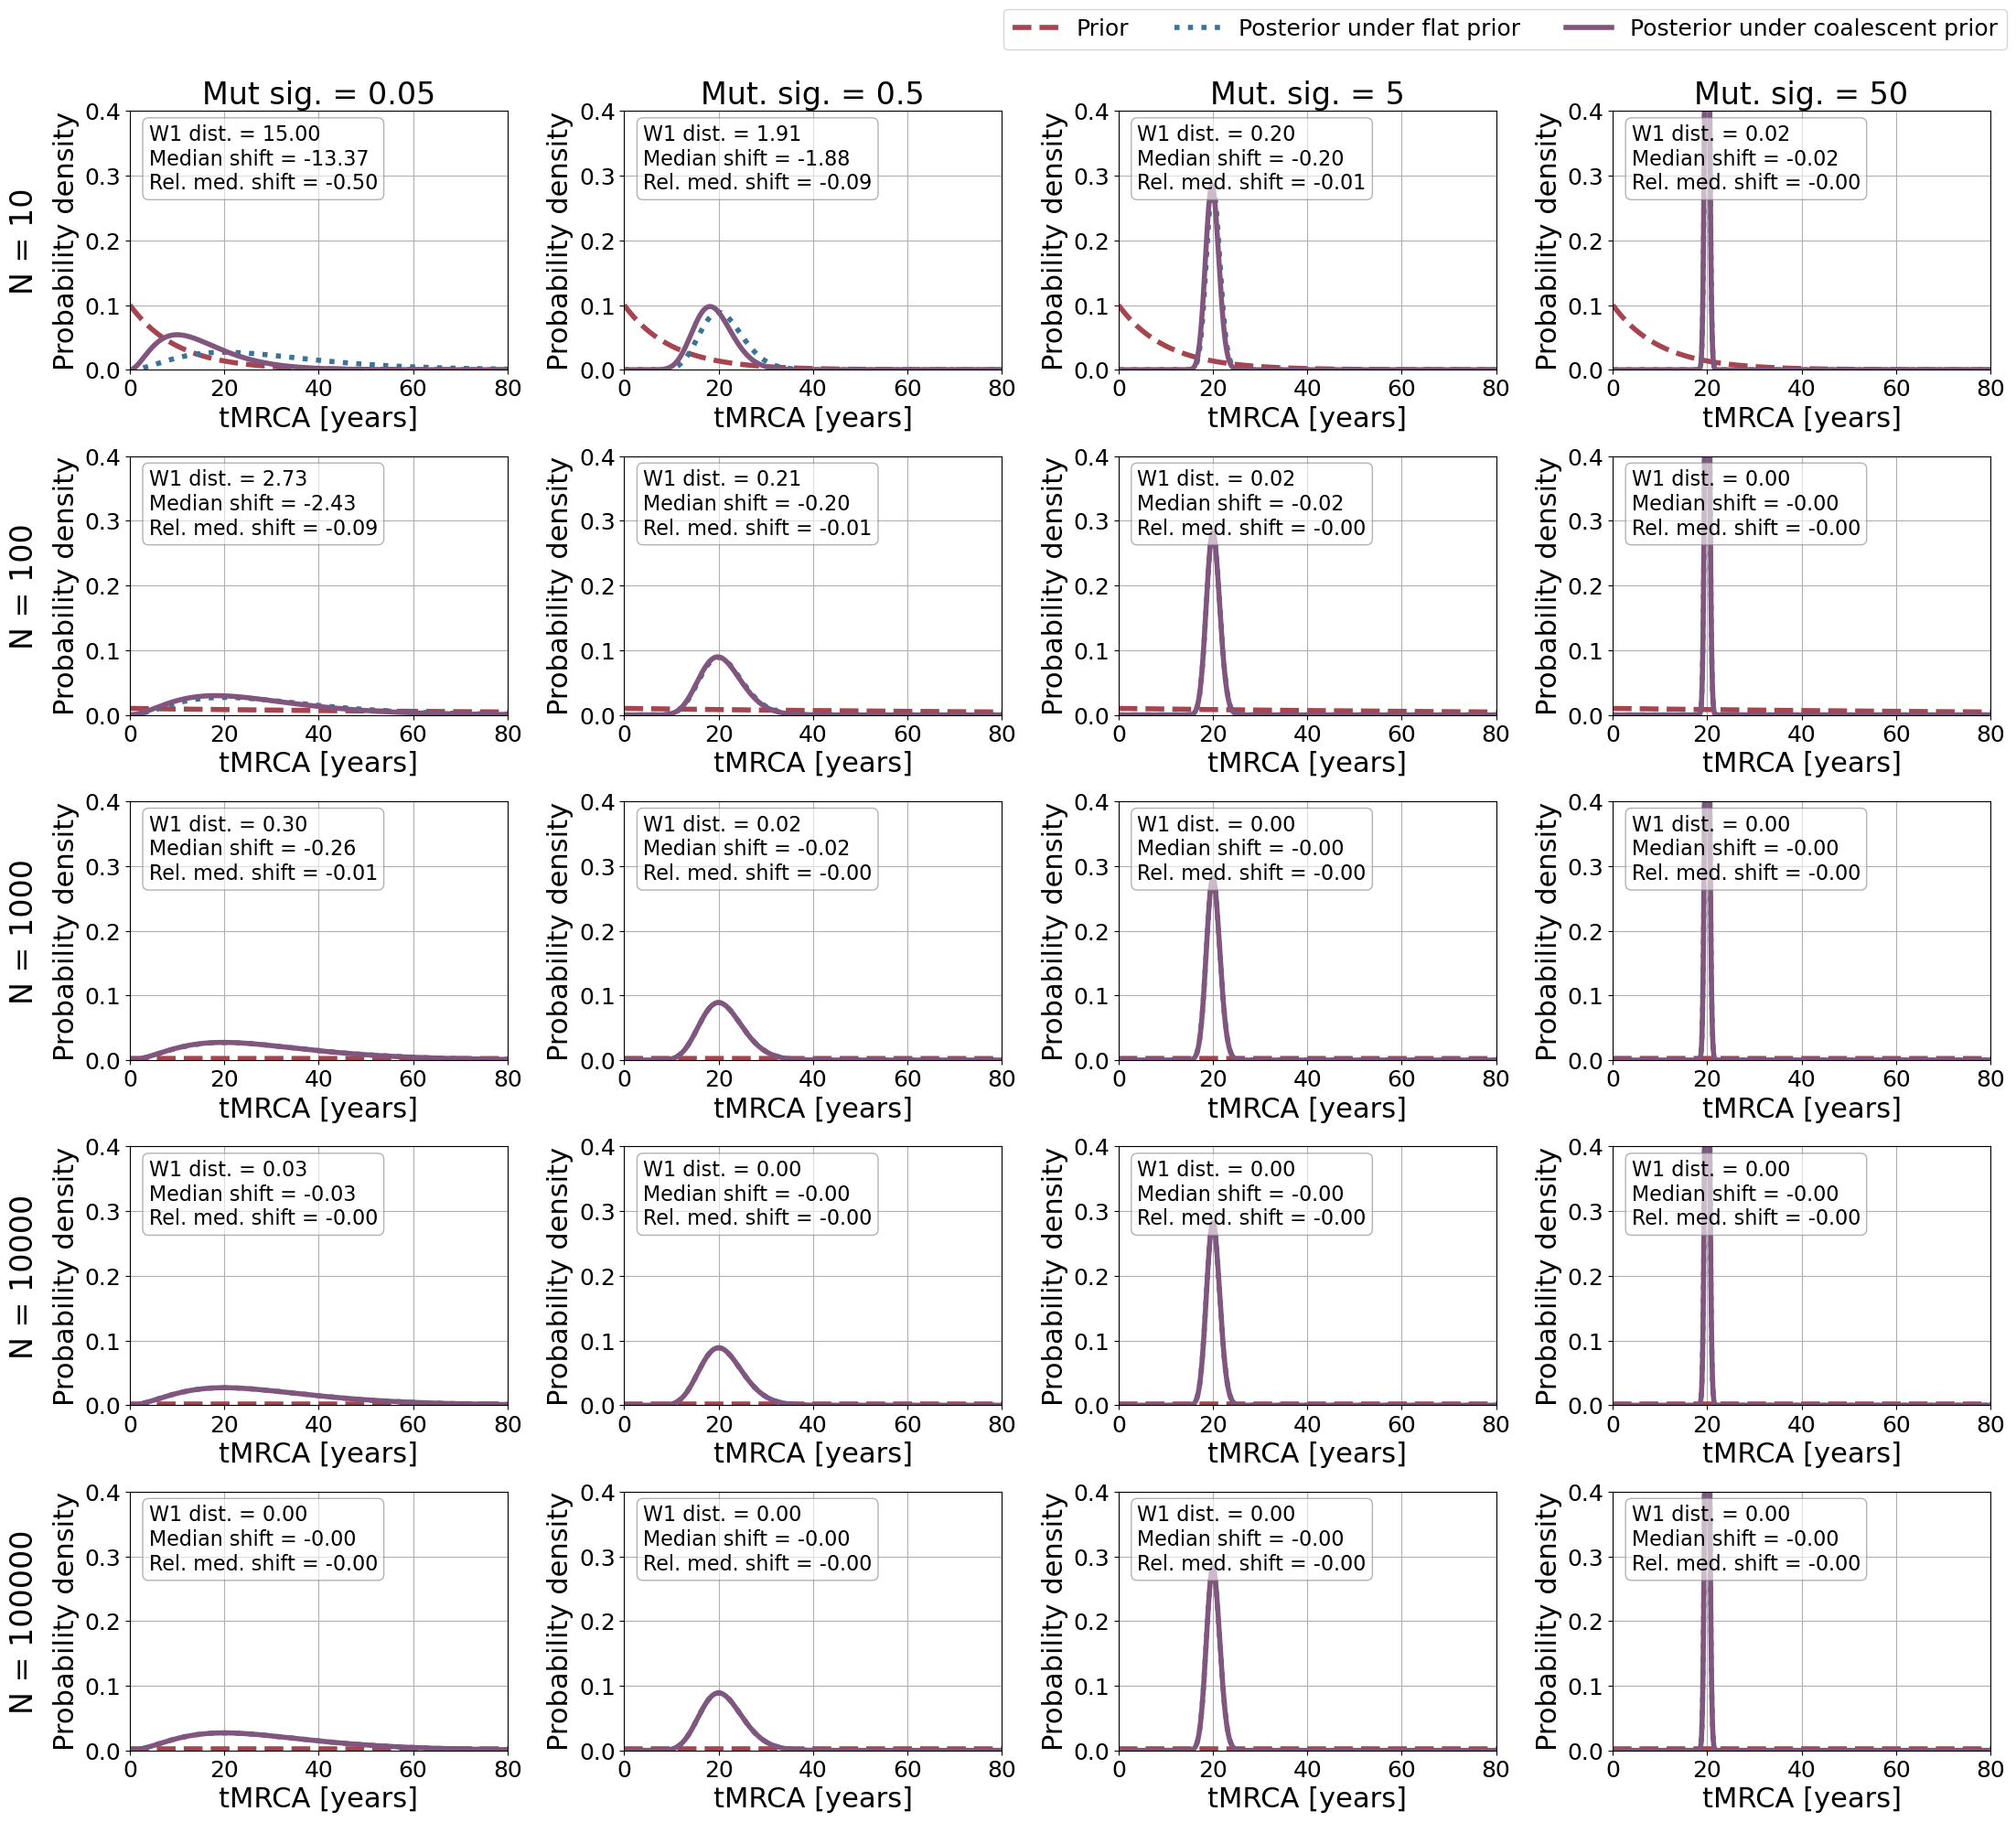

In [5]:
metrics = [
    (calculate_wasserstein_dist, "W1 dist.", {}),
    (calculate_median_shift, "Median shift", {'abs_value': False}),
    (calculate_rel_median_shift, "Rel. med. shift", {'abs_value': False}),
]
plot_tMRCA_constN(N_values, alpha_values, base_mu, base_k, t_max, L, metrics=metrics, title = "", time_scale = "years", x_max = 80, scale_mode = "area", figsize=(22, 20), y_range = (0, 0.4),
                  column_labels = ["Mut sig. = 0.05", "Mut. sig. = 0.5", "Mut. sig. = 5", "Mut. sig. = 50"], save_path = "figures/tMRCA_constN.pdf")


Population size 20 years ago (at expected tMRCA): [  2.47875218  18.31563889 135.33528324 367.87944117 818.73075308]


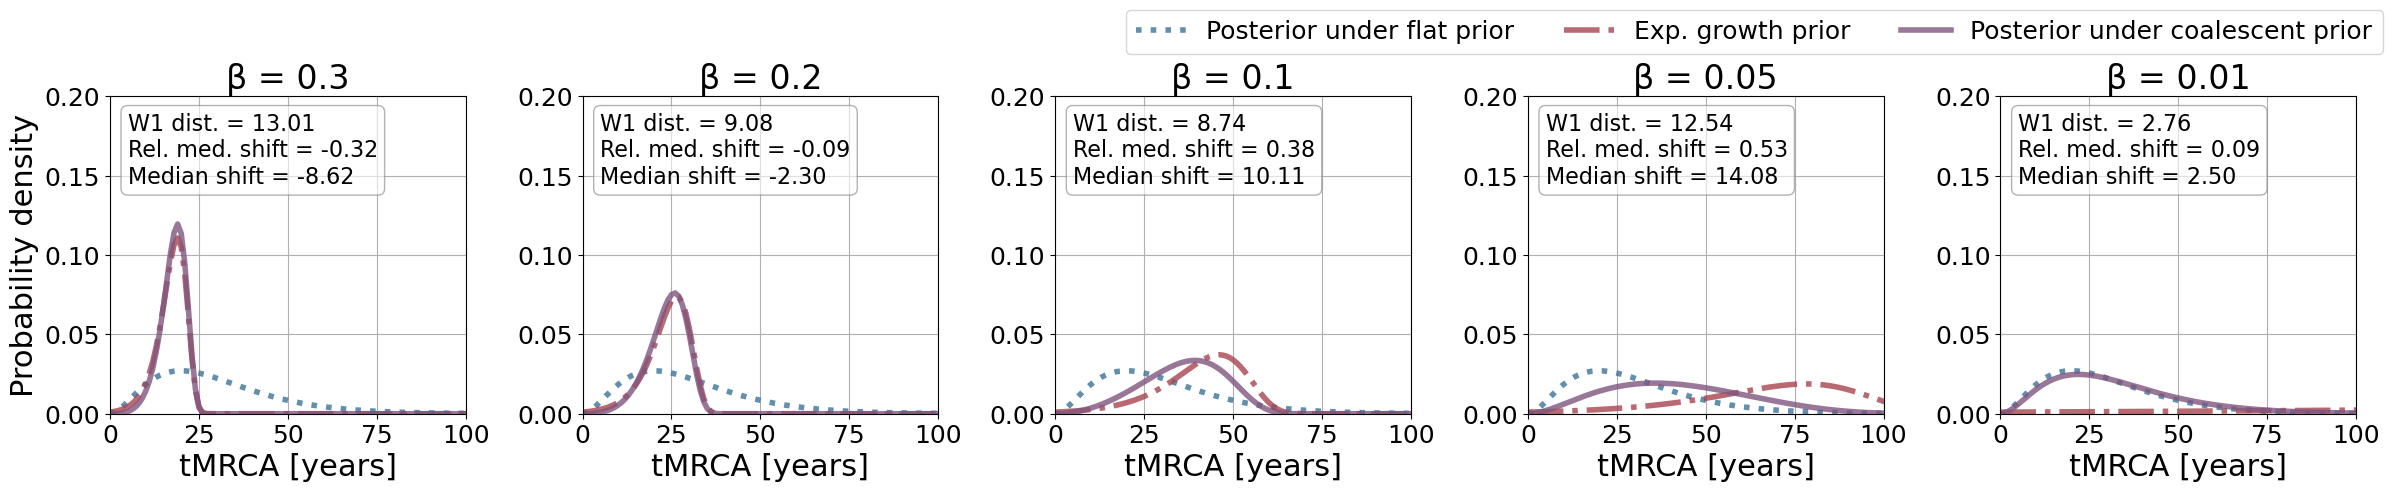

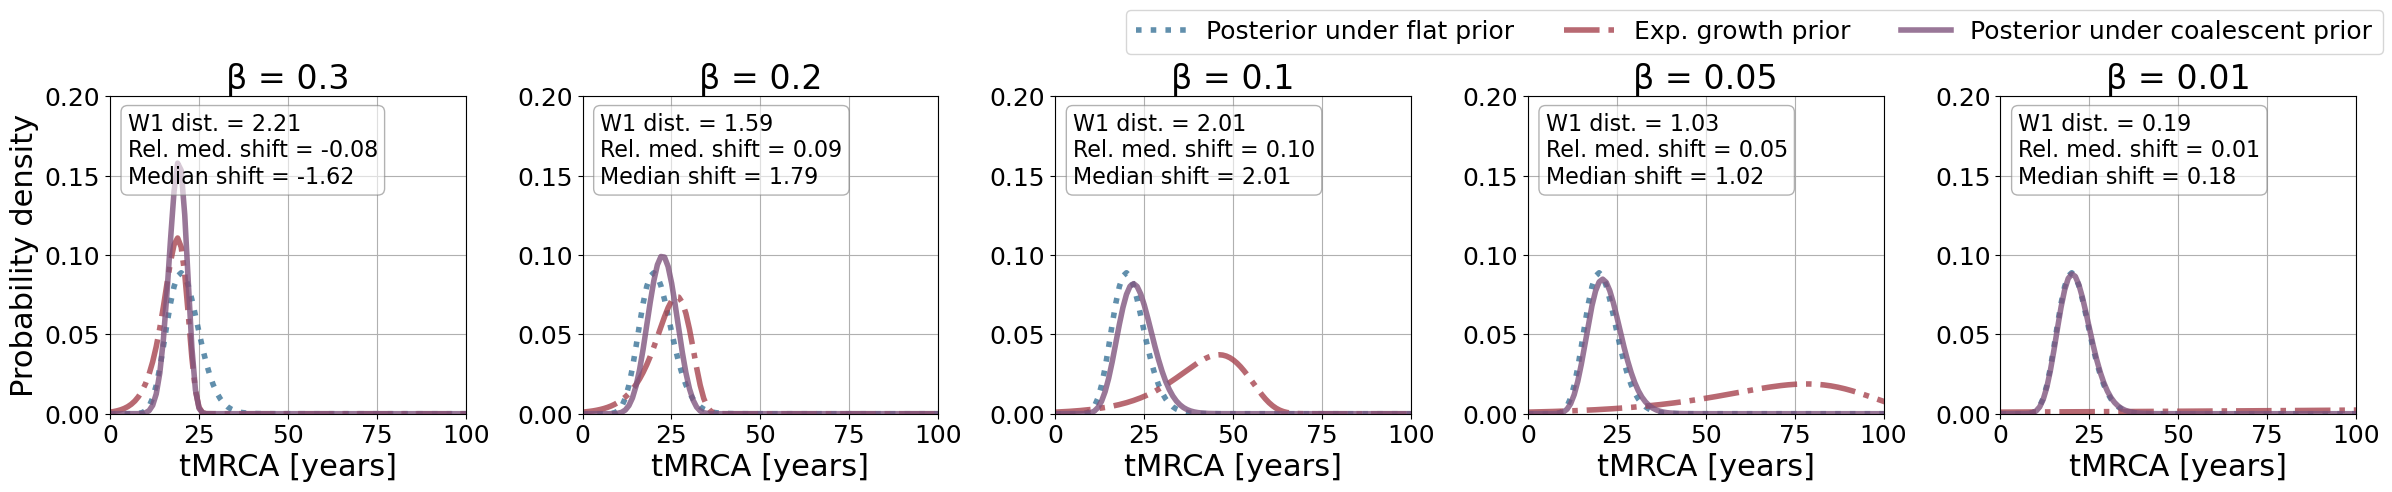

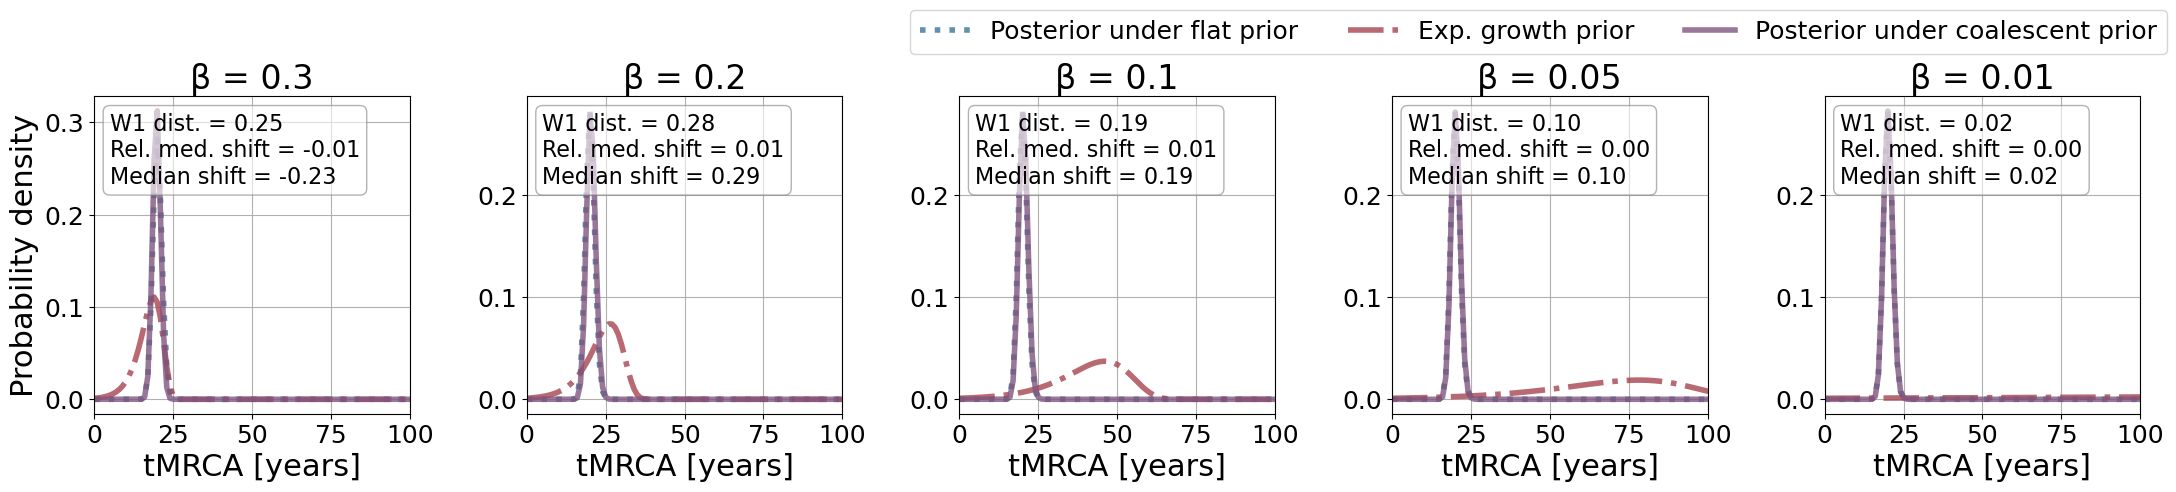

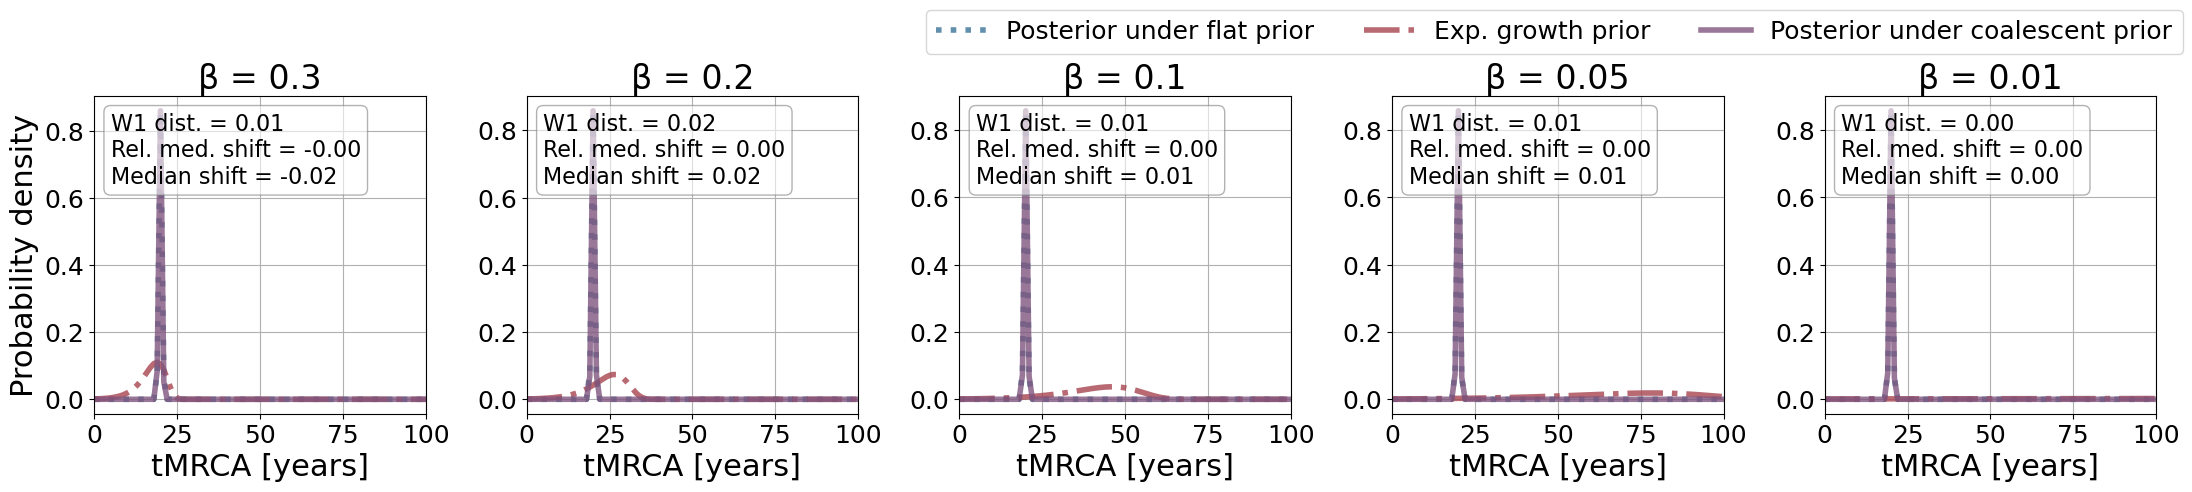

In [6]:
metrics = [
    (calculate_wasserstein_dist, "W1 dist.", {}),
    (calculate_rel_median_shift, "Rel. med. shift", {'abs_value': False}),
    (calculate_median_shift, "Median shift", {'abs_value': False}),
]

beta_vec_1000 = [0.3, 0.2, 0.1, 0.05, 0.01]
N_present = 1000
print(f"Population size 20 years ago (at expected tMRCA): {np.exp(-np.array(beta_vec_1000)*(t_MRCA_mle))*N_present}")


plot_tMRCA_expN_present(mu = base_mu * alpha_values[0], L= L, k_mut= base_k * alpha_values[0], N_present = N_present, beta_vec = beta_vec_1000, max_tmrca = t_max, N = None, metrics= metrics, plot_comparison_to_const=False, time_scale = "years", x_max = 100, y_range = (0,0.2), scale_mode = "area", save_path = "figures/tMRCA_expN_1000_005.pdf", figsize=(24, 5))
plot_tMRCA_expN_present(mu = base_mu * alpha_values[1], L= L, k_mut= base_k * alpha_values[1], N_present = N_present, beta_vec = beta_vec_1000, max_tmrca = t_max, N = None, metrics= metrics, plot_comparison_to_const=False, time_scale = "years", x_max = 100, y_range = (0,0.2),scale_mode = "area", save_path = "figures/tMRCA_expN_1000_05.pdf", figsize=(24, 5))
plot_tMRCA_expN_present(mu = base_mu * alpha_values[2], L= L, k_mut= base_k * alpha_values[2], N_present = N_present, beta_vec = beta_vec_1000, max_tmrca = t_max, N = None, metrics= metrics, plot_comparison_to_const=False, time_scale = "years", x_max = 100, scale_mode = "area", figsize=(22, 5))
plot_tMRCA_expN_present(mu = base_mu * alpha_values[3], L= L, k_mut= base_k * alpha_values[3], N_present = N_present, beta_vec = beta_vec_1000, max_tmrca = t_max, N = None, metrics= metrics, plot_comparison_to_const=False, time_scale = "years", x_max = 100, scale_mode = "area", figsize=(22, 5))


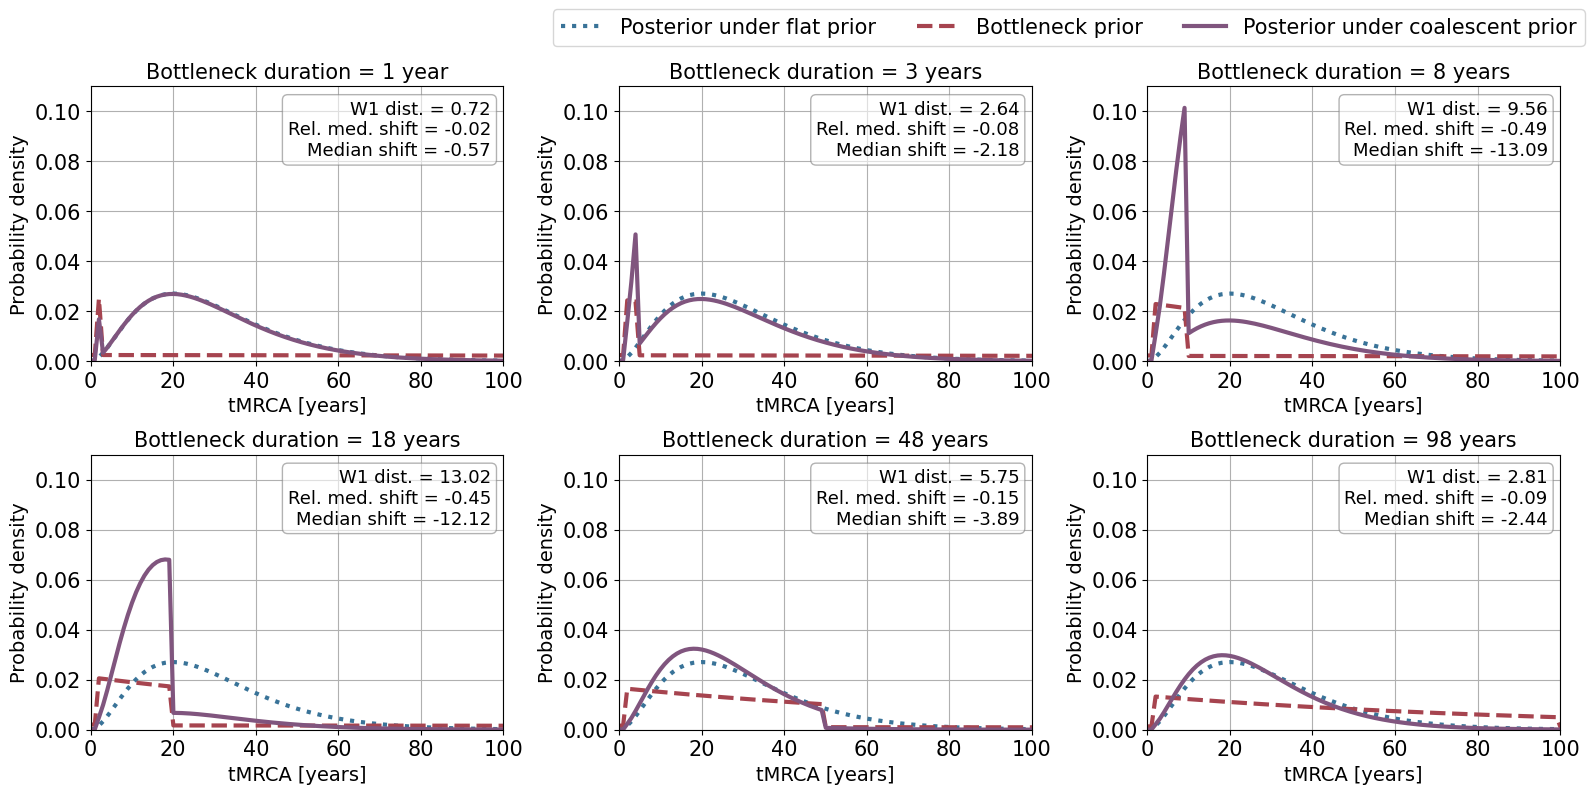

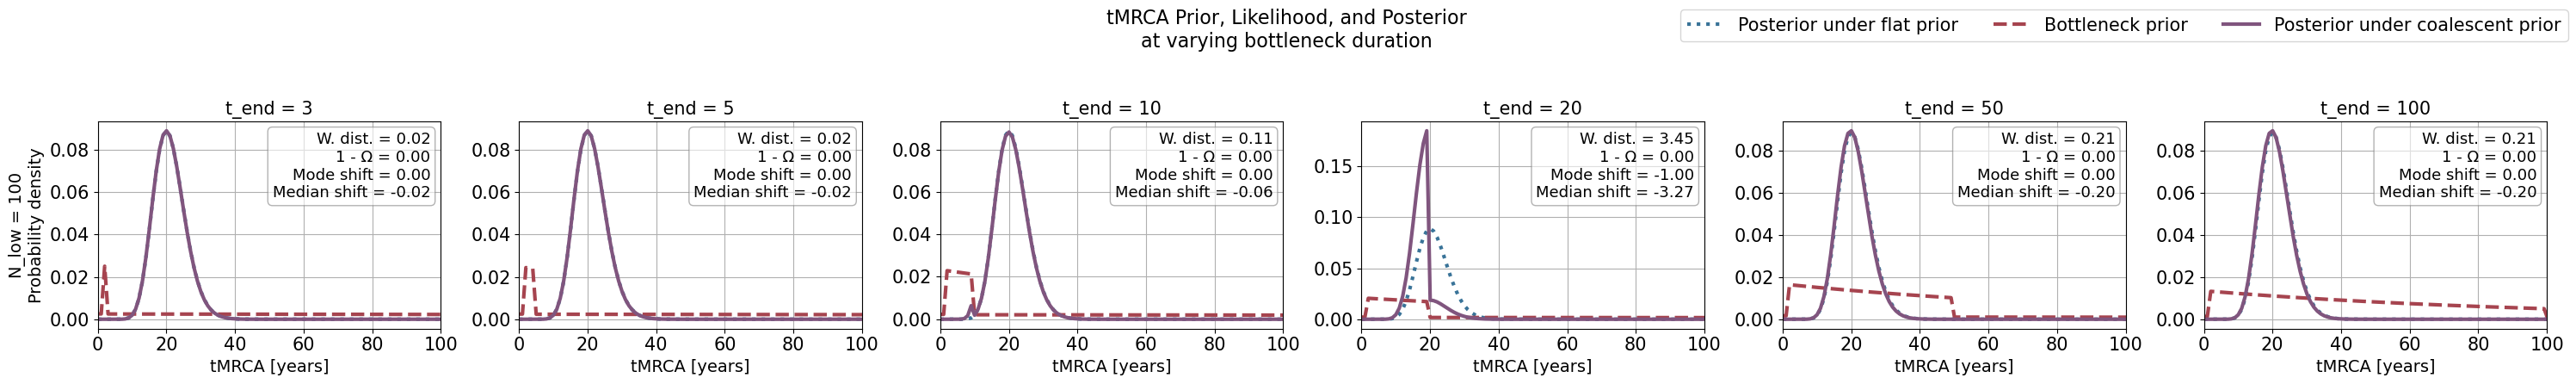

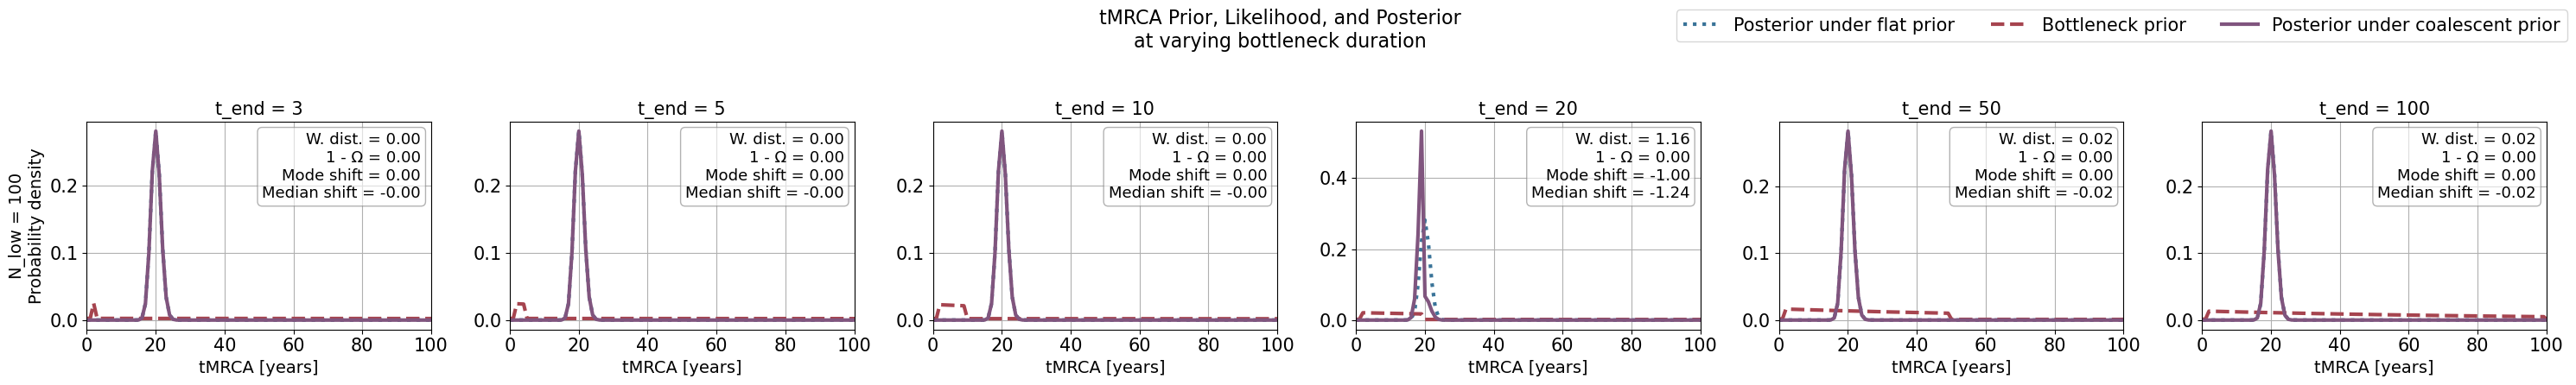

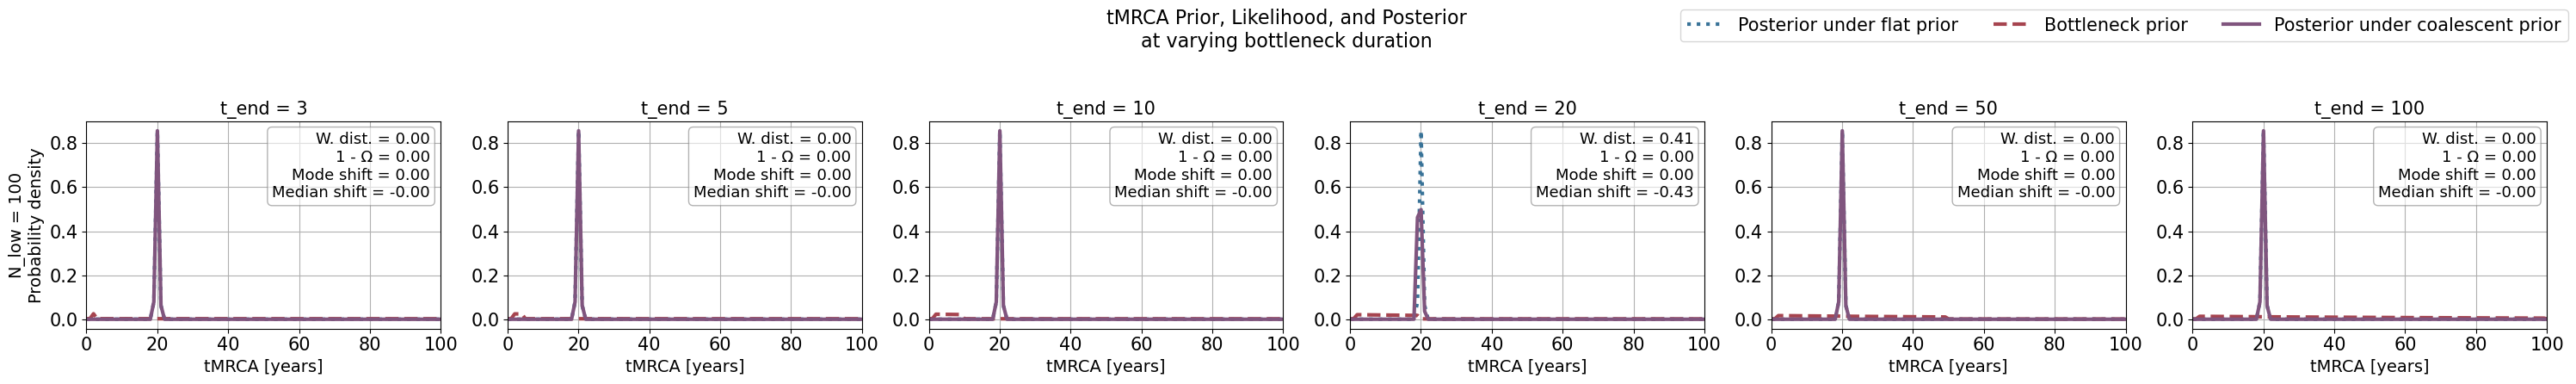

In [7]:
plot_tMRCA_bottleneck(base_mu * alpha_values[0], L, base_k * alpha_values[0], 1000, [100], 2, [3, 5, 10, 20, 50, 100], t_max, time_scale='years', x_max = 100, scale_mode = "area", figsize = (16,8), max_cols = 3,
                      title = "", metrics = metrics, save_path = "figures/tMRCA_bottleneck_005.pdf", y_range = (0, 0.11),
                      tile_labels = ["Bottleneck duration = 1 year", "Bottleneck duration = 3 years", "Bottleneck duration = 8 years", "Bottleneck duration = 18 years", "Bottleneck duration = 48 years", "Bottleneck duration = 98 years"])
plot_tMRCA_bottleneck(base_mu * alpha_values[1], L, base_k * alpha_values[1], 1000, [100], 2, [3, 5, 10, 20, 50, 100], t_max, time_scale='years', x_max = 100, scale_mode = "area")
plot_tMRCA_bottleneck(base_mu * alpha_values[2], L, base_k * alpha_values[2], 1000, [100], 2, [3, 5, 10,20, 50, 100], t_max, time_scale='years', x_max = 100, scale_mode = "area")
plot_tMRCA_bottleneck(base_mu * alpha_values[3], L, base_k * alpha_values[3], 1000, [100], 2, [3, 5, 10, 20, 50, 100], t_max, time_scale='years', x_max = 100, scale_mode = "area")


## Summary plots

### Varying mutational signal

In [8]:
pathogen_params = {
    "0.05 (part of bacterial genome)":
    {
        "N_values": [10, 100, 1000, 10000, 100000],
        "mu": base_mu * 0.01,
        "k": base_k * 0.01,
        "L": L,
        "t_max": t_max,
    },
    "0.5 (bacterial genome)":
    {
        "N_values": [10, 100, 1000, 10000, 100000],
        "mu": base_mu * 0.1,
        "k": base_k * 0.1,
        "L": L,
        "t_max": t_max,
    },
    "5 (typical RNA virus gene)":
    {
        "N_values": [10, 100, 1000, 10000, 100000],
        "mu": base_mu,
        "k": base_k,
        "L": L,
        "t_max": t_max,
    },
    "50 (upper bound for RNA virus genome)":
    {
        "N_values": [10, 100, 1000, 10000, 100000],
        "mu": base_mu * 10,
        "k": base_k * 10,
        "L": L,
        "t_max": t_max,
    }
}

pathogen_const_df = create_prior_influence_metric_df_const_pathogen(pathogen_params)
pathogen_exp_growth_df = create_prior_influence_metric_df_exp_pathogen(pathogen_params, N = 1000, beta_vec = [1, 0.7, 0.5, 0.3, 0.2, 0.15, 0.1, 0.09, 0.08,0.07,0.06, 0.05, 0.04, 0.03, 0.02,0.01])
pathogen_bottleneck_df = create_prior_influence_metric_df_bottleneck_pathogen(pathogen_params, N_high = 1000, N_low = 100, t_bottleneck_end_vec = [3, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100], t_bottleneck_start = 2)

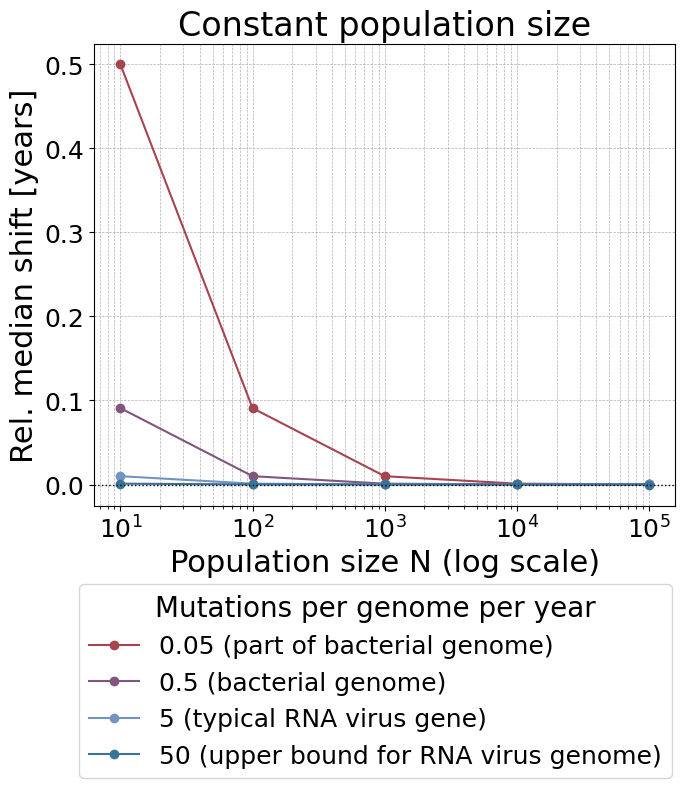

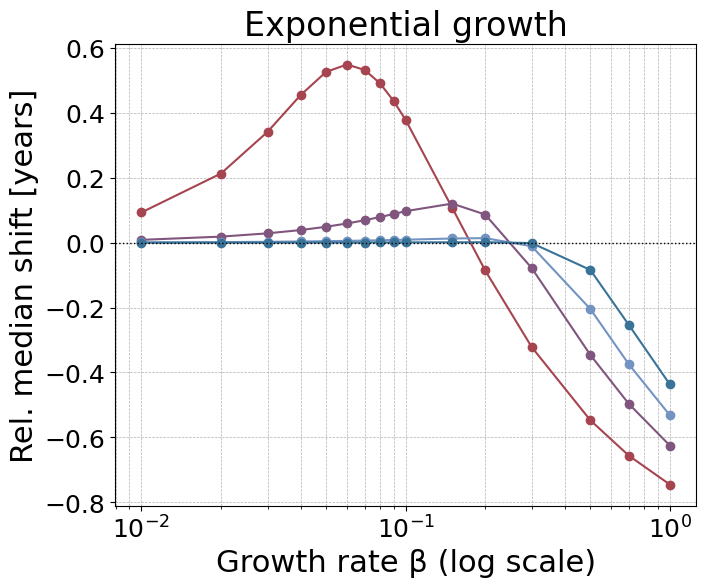

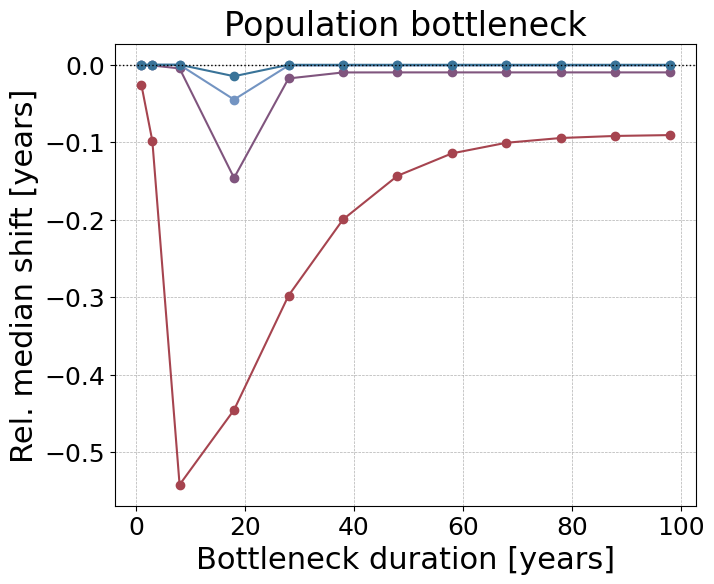

In [9]:
# Relative median shift

plot_pathogen_error_summary(df_const = pathogen_const_df, title = "", error_col="rel_median_shift", y_label = "Rel. median shift [years]", legend_position="below", save_path = "figures/pathogen_error_summary_const.pdf")
plot_pathogen_error_summary(df_growth =pathogen_exp_growth_df, title = "", error_col="rel_median_shift", y_label = "Rel. median shift [years]", legend_position="none", save_path = "figures/pathogen_error_summary_growth.pdf")
plot_pathogen_error_summary(df_bottleneck = pathogen_bottleneck_df, title = "", error_col="rel_median_shift", y_label = "Rel. median shift [years]", legend_position="none", save_path = "figures/pathogen_error_summary_bottleneck.pdf")

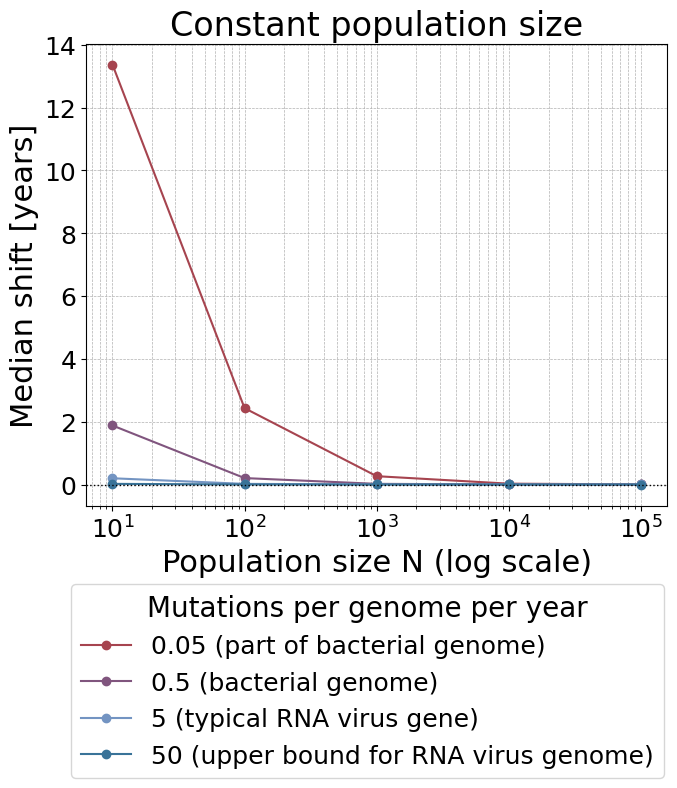

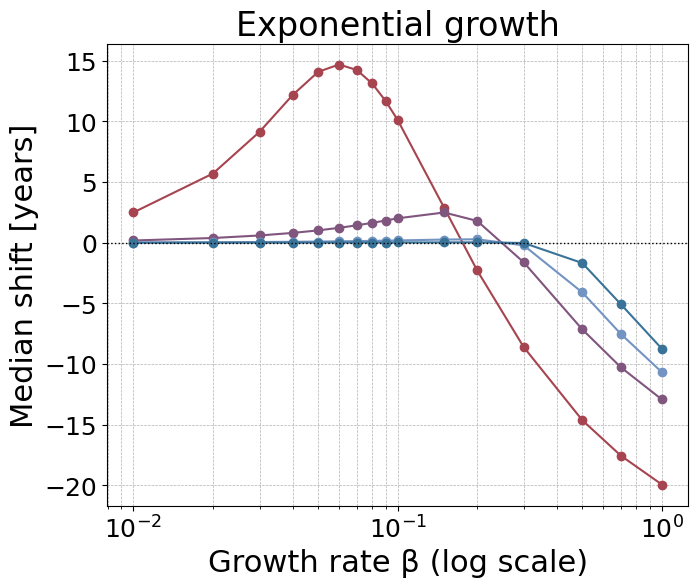

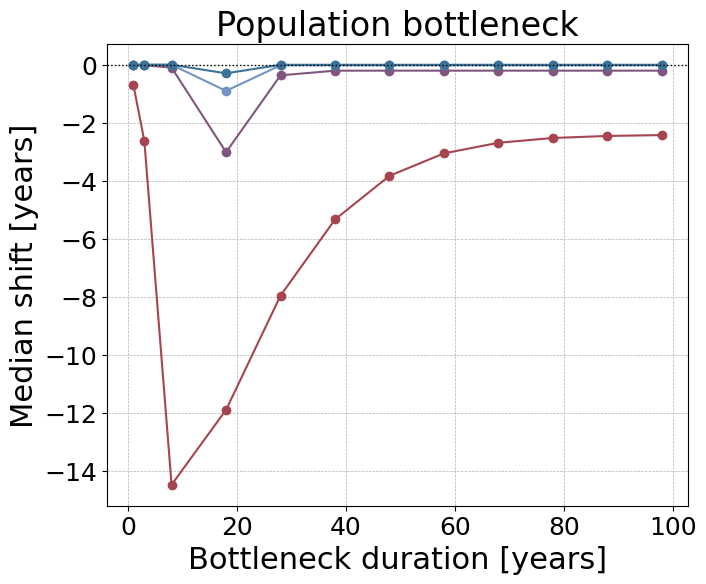

In [10]:
# Median shift

plot_pathogen_error_summary(df_const = pathogen_const_df, title = "", error_col="median_shift", y_label = "Median shift [years]", legend_position="below", save_path = "figures/pathogen_error_summary_const_median.pdf")
plot_pathogen_error_summary(df_growth =pathogen_exp_growth_df, title = "", error_col="median_shift", y_label = "Median shift [years]", legend_position="none", save_path = "figures/pathogen_error_summary_growth_median.pdf")
plot_pathogen_error_summary(df_bottleneck = pathogen_bottleneck_df, title = "", error_col="median_shift", y_label = "Median shift [years]", legend_position="none", save_path = "figures/pathogen_error_summary_bottleneck_median.pdf")

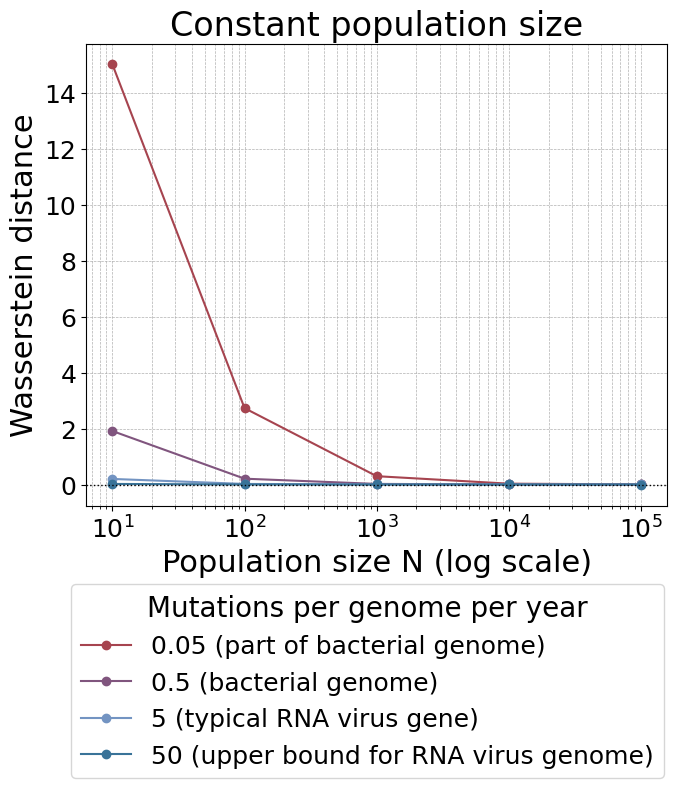

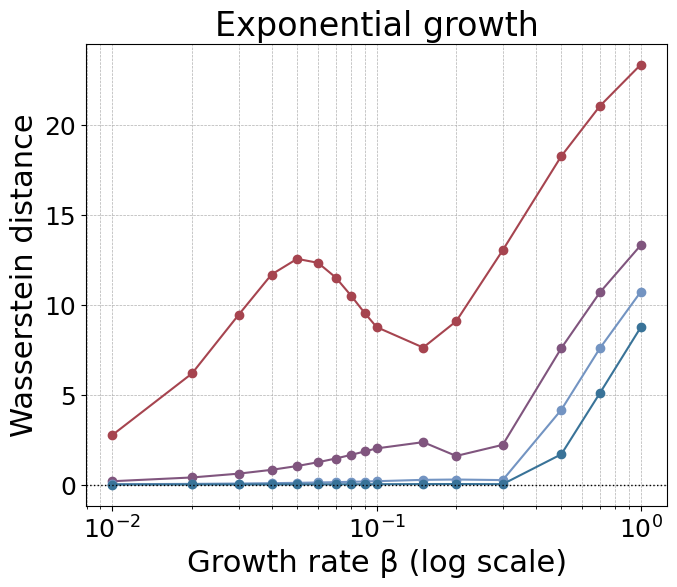

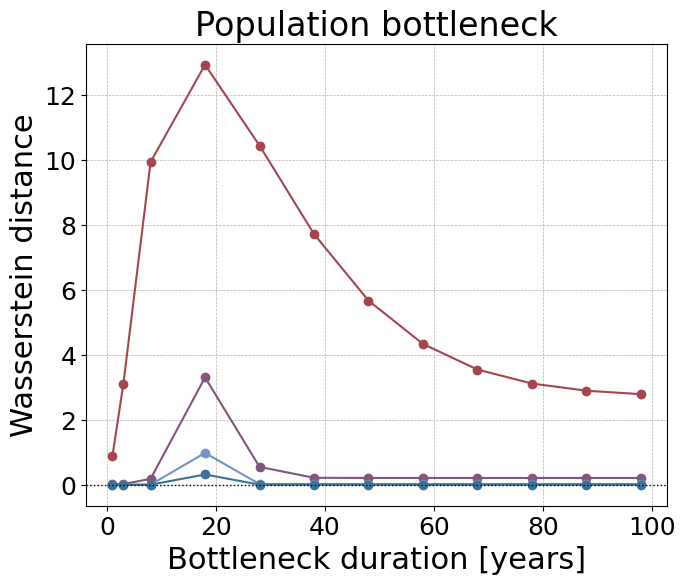

In [11]:
# Wasserstein-1 distance

plot_pathogen_error_summary(df_const = pathogen_const_df, title = "", error_col="wasserstein_dist", y_label = "Wasserstein distance", legend_position="below", save_path = "figures/pathogen_error_summary_const_wasserstein.pdf")
plot_pathogen_error_summary(df_growth =pathogen_exp_growth_df, title = "", error_col="wasserstein_dist", y_label = "Wasserstein distance", legend_position="none", save_path = "figures/pathogen_error_summary_growth_wasserstein.pdf")
plot_pathogen_error_summary(df_bottleneck = pathogen_bottleneck_df, title = "", error_col="wasserstein_dist", y_label = "Wasserstein distance", legend_position="none", save_path = "figures/pathogen_error_summary_bottleneck_wasserstein.pdf")

### More parameter settings

In [12]:
# fix 0.5 mutations per genome per year (a bit higher signal than tuberculosis setting)
N_beta = {100: [1, 0.7, 0.5, 0.3, 0.2, 0.15, 0.1, 0.09, 0.08,0.07,0.06, 0.05, 0.04, 0.03, 0.02,0.01], 1000: [1, 0.7, 0.5, 0.3, 0.2, 0.15, 0.1, 0.09, 0.08,0.07,0.06, 0.05, 0.04, 0.03, 0.02,0.01], 10000:[1, 0.7, 0.5, 0.3, 0.2, 0.15, 0.1, 0.09, 0.08,0.07,0.06, 0.05, 0.04, 0.03, 0.02,0.01], 100000:[1, 0.7, 0.5, 0.3, 0.2, 0.15, 0.1, 0.09, 0.08,0.07,0.06, 0.05, 0.04, 0.03, 0.02,0.01]}

exp_tuberculosis_df = create_prior_influence_metric_df_pathogen_exp(N_beta, base_mu * alpha_values[1], base_k * alpha_values[1], L, t_max)
exp_tuberculosis_df

tuberculosis_bottleneck_df = create_prior_influence_metric_df_bottleneck(N_high = 1000, N_low_values = [100, 300, 500, 800], t_bottleneck_end_vec = [3, 5, 10, 20, 30, 40, 50,], t_bottleneck_start = 2, alpha_values = [0.1], base_mu = base_mu, base_k = base_k, L = L, t_max = t_max)

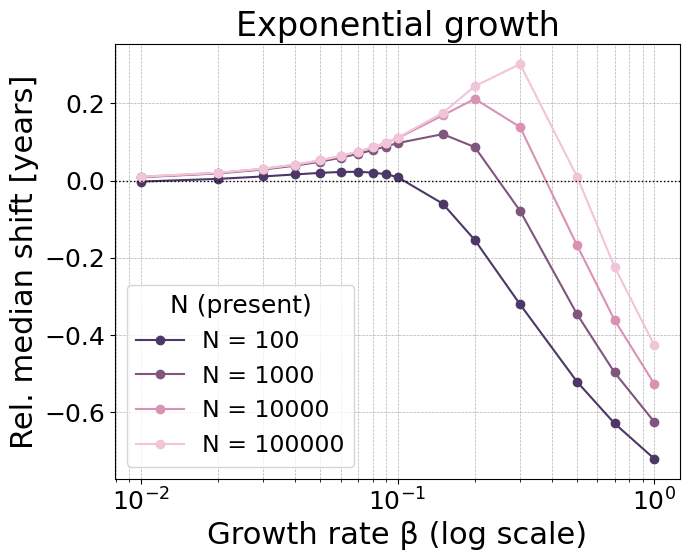

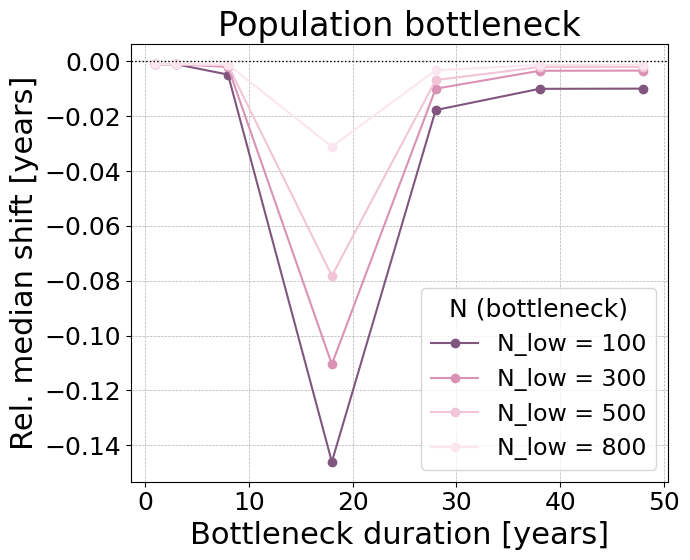

In [13]:
plot_metric_summary(df_exp = exp_tuberculosis_df, title = "Median shift comparison for different population size models", metric = 'rel_median_shift', y_label = "Rel. median shift [years]", legend_title = "N (present)", save_path = "figures/rel_median_shift_comparison_exp.pdf")
plot_metric_summary(df_bottleneck = tuberculosis_bottleneck_df, title = "Median shift comparison for different population size models", metric = 'rel_median_shift', y_label = "Rel. median shift [years]", legend_title = "N (bottleneck)", save_path = "figures/rel_median_shift_comparison_bottleneck.pdf")

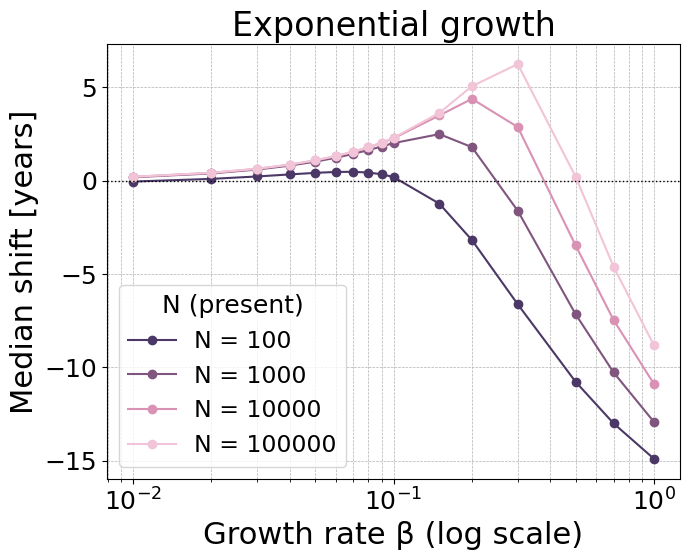

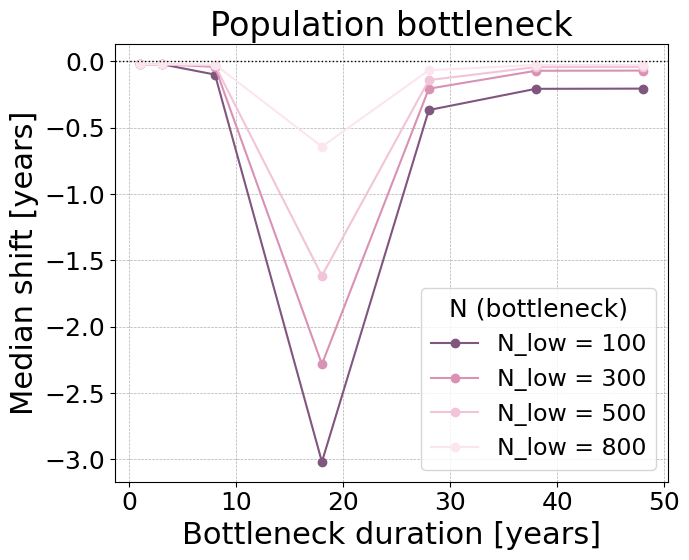

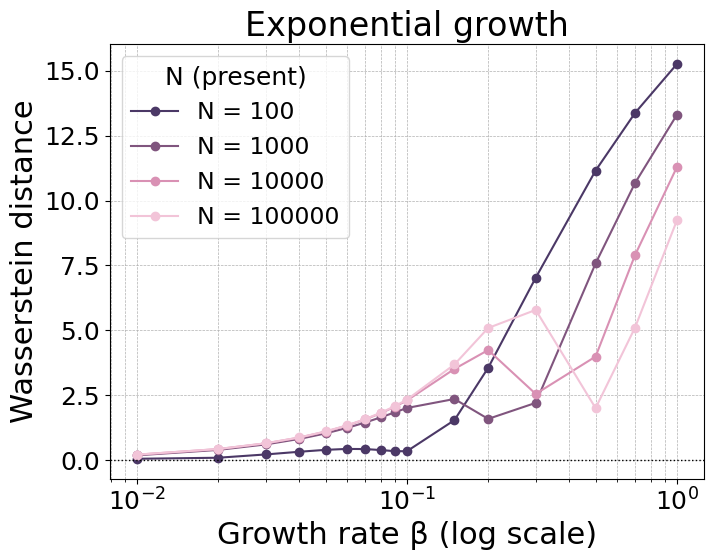

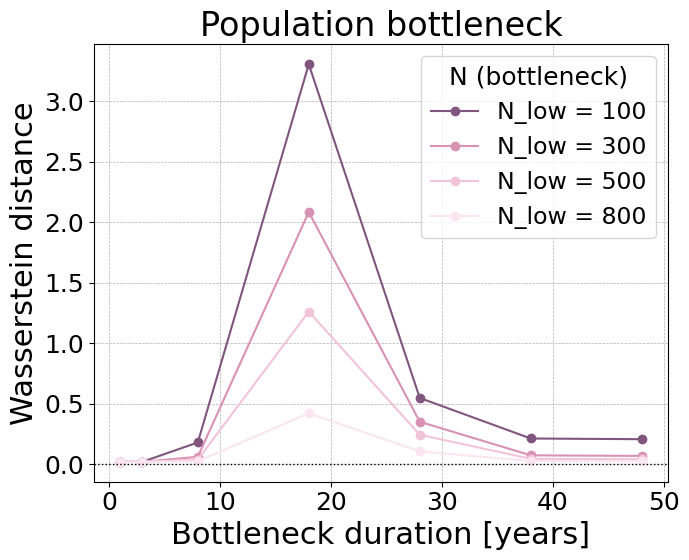

In [14]:
# additional metrics

plot_metric_summary(df_exp = exp_tuberculosis_df, title = "Median shift comparison for different population size models", metric = 'median_shift', y_label = "Median shift [years]", legend_title = "N (present)", save_path = "figures/median_shift_comparison_exp.pdf")
plot_metric_summary(df_bottleneck = tuberculosis_bottleneck_df, title = "Median shift comparison for different population size models", metric = 'median_shift', y_label = "Median shift [years]", legend_title = "N (bottleneck)", save_path = "figures/median_shift_comparison_bottleneck.pdf")

plot_metric_summary(df_exp = exp_tuberculosis_df, title = "Wasserstein distance comparison for different population size models", metric = 'wasserstein_dist', y_label = "Wasserstein distance", legend_title = "N (present)", save_path = "figures/wasserstein_comparison_exp.pdf")
plot_metric_summary(df_bottleneck = tuberculosis_bottleneck_df, title = "Wasserstein distance comparison for different population size models", metric = 'wasserstein_dist', y_label = "Wasserstein distance", legend_title = "N (bottleneck)", save_path = "figures/wasserstein_comparison_bottleneck.pdf")